In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')

In [2]:
import os

def load_bank_data():
    # UCI files use ';' and some Kaggle copies use ','. sep=None lets pandas detect it.
    for name in ['bank-full.csv', 'bank.csv', 'bank-additional-full.csv']:
        if os.path.exists(name):
            print('Loaded real dataset:', name)
            return pd.read_csv(name, sep=None, engine='python'), False

    # Fallback so the notebook still runs without the file
    print('WARNING: no bank CSV found. Using SYNTHETIC demo data - NOT the real dataset.')
    rng = np.random.default_rng(42)
    n = 4500
    df = pd.DataFrame({
        'age': rng.normal(41, 10, n).clip(18, 90).round().astype(int),
        'job': rng.choice(['management', 'blue-collar', 'technician', 'admin.', 'services', 'retired', 'student', 'self-employed'], n),
        'marital': rng.choice(['married', 'single', 'divorced'], n, p=[0.6, 0.3, 0.1]),
        'education': rng.choice(['primary', 'secondary', 'tertiary', 'unknown'], n, p=[0.15, 0.5, 0.3, 0.05]),
        'default': rng.choice(['no', 'yes'], n, p=[0.98, 0.02]),
        'balance': rng.gamma(2, 900, n).round().astype(int) - 300,
        'housing': rng.choice(['yes', 'no'], n),
        'loan': rng.choice(['no', 'yes'], n, p=[0.84, 0.16]),
        'contact': rng.choice(['cellular', 'telephone', 'unknown'], n, p=[0.65, 0.07, 0.28]),
        'day': rng.integers(1, 31, n),
        'month': rng.choice(['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], n),
        'duration': rng.gamma(2, 130, n).round().astype(int),
        'campaign': rng.integers(1, 10, n),
        'pdays': np.where(rng.random(n) < 0.8, -1, rng.integers(1, 400, n)),
        'previous': rng.integers(0, 4, n),
        'poutcome': rng.choice(['unknown', 'failure', 'success', 'other'], n, p=[0.8, 0.1, 0.04, 0.06]),
    })
    score = (-3.2 + 0.0025 * df['duration'] + 0.35 * (df['education'] == 'tertiary')
             + 2.2 * (df['poutcome'] == 'success') + 0.5 * df['job'].isin(['student', 'retired']))
    df['y'] = np.where(rng.random(n) < 1 / (1 + np.exp(-score)), 'yes', 'no')
    return df, True

bank_df, USING_SYNTHETIC = load_bank_data()

bank_df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,44,retired,married,secondary,no,632,no,no,cellular,22,jan,166,6,-1,0,unknown,no
1,31,technician,married,secondary,no,307,yes,no,cellular,17,apr,680,7,-1,3,failure,no
2,49,self-employed,married,tertiary,no,351,no,yes,cellular,14,sep,164,7,-1,1,unknown,no
3,50,student,married,secondary,no,3348,yes,yes,unknown,20,may,214,6,21,1,unknown,no
4,21,self-employed,married,primary,yes,820,no,no,cellular,27,mar,85,3,-1,2,unknown,no
5,28,blue-collar,married,tertiary,no,87,no,no,unknown,16,jun,60,7,183,3,unknown,no
6,42,retired,divorced,secondary,no,754,yes,no,cellular,21,mar,384,2,-1,1,unknown,no
7,38,management,married,tertiary,no,1723,yes,no,cellular,18,oct,410,9,-1,1,unknown,no
8,41,management,married,secondary,no,1168,yes,no,cellular,20,feb,104,8,-1,1,unknown,no
9,32,self-employed,married,secondary,no,3678,yes,no,cellular,21,mar,183,3,-1,1,unknown,no


In [3]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4500 non-null   int64 
 1   job        4500 non-null   object
 2   marital    4500 non-null   object
 3   education  4500 non-null   object
 4   default    4500 non-null   object
 5   balance    4500 non-null   int64 
 6   housing    4500 non-null   object
 7   loan       4500 non-null   object
 8   contact    4500 non-null   object
 9   day        4500 non-null   int64 
 10  month      4500 non-null   object
 11  duration   4500 non-null   int64 
 12  campaign   4500 non-null   int64 
 13  pdays      4500 non-null   int64 
 14  previous   4500 non-null   int64 
 15  poutcome   4500 non-null   object
 16  y          4500 non-null   object
dtypes: int64(7), object(10)
memory usage: 597.8+ KB


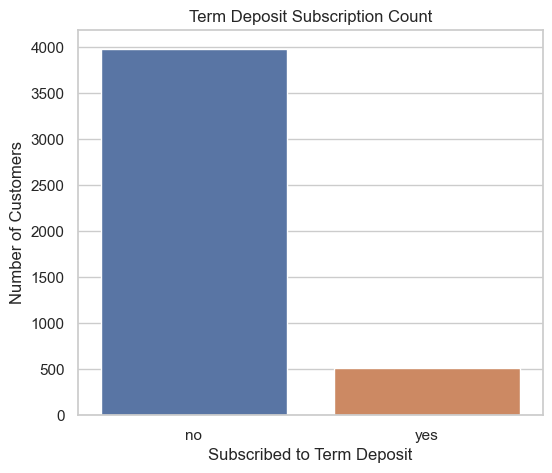

y
no     3985
yes     515
Name: count, dtype: int64
y
no     88.6 %
yes    11.4 %
Name: proportion, dtype: object


In [4]:
plt.figure(figsize=(6, 5))
sns.countplot(data=bank_df, x='y', hue='y', legend=False, order=['no', 'yes'])
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')
plt.title('Term Deposit Subscription Count')
plt.show()

print(bank_df['y'].value_counts())
print((bank_df['y'].value_counts(normalize=True) * 100).round(1).astype(str) + ' %')

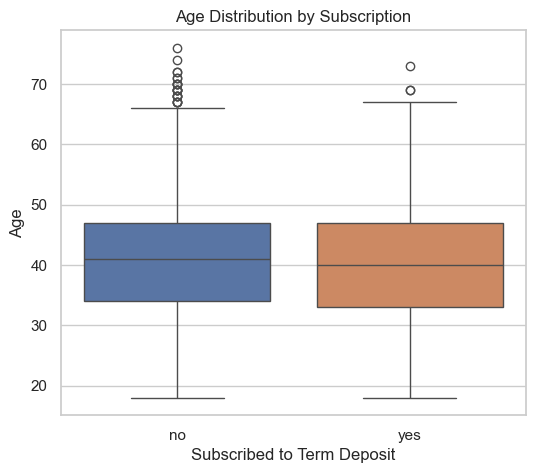

      count  mean   std   min   25%   50%   75%   max
y                                                    
no   3985.0  40.9   9.9  18.0  34.0  41.0  47.0  76.0
yes   515.0  40.5  10.0  18.0  33.0  40.0  47.0  73.0


In [5]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=bank_df, x='y', y='age', hue='y', legend=False, order=['no', 'yes'])
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Age')
plt.title('Age Distribution by Subscription')
plt.show()

print(bank_df.groupby('y')['age'].describe().round(1))

   education  subscribed_pct
3    unknown            15.0
2   tertiary            14.0
1  secondary            10.0
0    primary             9.9


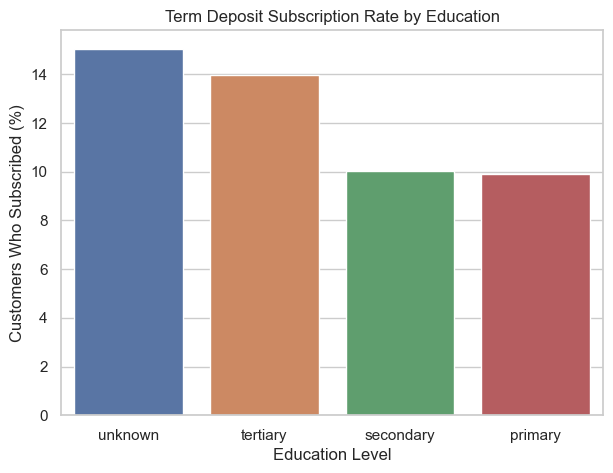

In [6]:
edu_pct = (bank_df.groupby('education')['y']
           .apply(lambda s: (s == 'yes').mean() * 100)
           .reset_index(name='subscribed_pct')
           .sort_values('subscribed_pct', ascending=False))
print(edu_pct.round(1))

plt.figure(figsize=(7, 5))
sns.barplot(data=edu_pct, x='education', y='subscribed_pct', hue='education', legend=False)
plt.xlabel('Education Level')
plt.ylabel('Customers Who Subscribed (%)')
plt.title('Term Deposit Subscription Rate by Education')
plt.show()

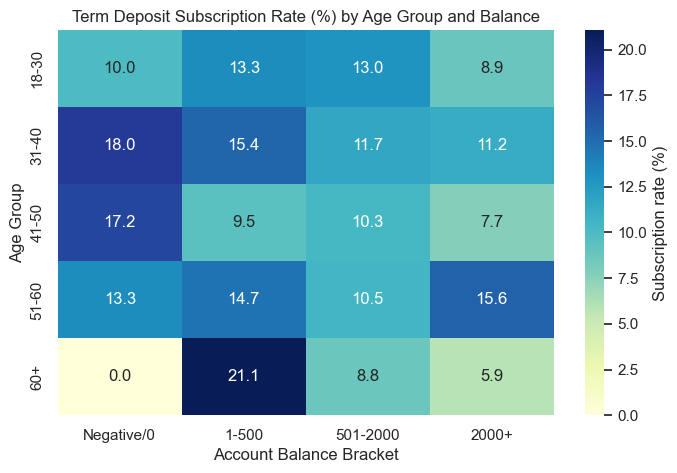

In [7]:
df = bank_df.copy()
df['subscribed'] = (df['y'] == 'yes').astype(int)
df['age_group'] = pd.cut(df['age'], bins=[17, 30, 40, 50, 60, 100],
                         labels=['18-30', '31-40', '41-50', '51-60', '60+'])
df['balance_bracket'] = pd.cut(df['balance'], bins=[-np.inf, 0, 500, 2000, np.inf],
                               labels=['Negative/0', '1-500', '501-2000', '2000+'])

rate = (df.pivot_table(index='age_group', columns='balance_bracket', values='subscribed',
                       aggfunc='mean', observed=True) * 100)

plt.figure(figsize=(8, 5))
sns.heatmap(rate, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': 'Subscription rate (%)'})
plt.xlabel('Account Balance Bracket')
plt.ylabel('Age Group')
plt.title('Term Deposit Subscription Rate (%) by Age Group and Balance')
plt.show()

In [8]:
overall = (bank_df['y'] == 'yes').mean() * 100
best_edu = edu_pct.iloc[0]
job_pct = bank_df.groupby('job')['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values(ascending=False)
pout_pct = bank_df.groupby('poutcome')['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values(ascending=False)

if USING_SYNTHETIC:
    print('NOTE: these numbers come from SYNTHETIC data - rerun with the real CSV before reporting them.\n')
print(f'Overall subscription rate: {overall:.1f}%')
print(f'Education with highest rate: {best_edu["education"]} ({best_edu["subscribed_pct"]:.1f}%)')
print(f'Job with highest rate: {job_pct.index[0]} ({job_pct.iloc[0]:.1f}%)')
print(f'Best previous-campaign outcome: {pout_pct.index[0]} ({pout_pct.iloc[0]:.1f}%)')

NOTE: these numbers come from SYNTHETIC data - rerun with the real CSV before reporting them.

Overall subscription rate: 11.4%
Education with highest rate: unknown (15.0%)
Job with highest rate: retired (16.1%)
Best previous-campaign outcome: success (47.3%)
